# Notebook 03 — Model Training & AutoML

## Objectif

L'objectif de ce notebook est d'entraîner et de comparer plusieurs modèles de Machine Learning pour prédire le Churn des clients.

Les étapes :
1. Charger les données prétraitées.
2. Initialiser plusieurs algorithmes.
3. Entraîner les modèles.
4. Évaluer leurs performances.
5. Comparer les résultats.
6. Sélectionner automatiquement le meilleur modèle selon le F1-score.
7. Sauvegarder le modèle sélectionné.

**Important :** le meilleur modèle est sélectionné sur les performances obtenues sur le jeu de test. Pour un projet de production, il faudra réserver un jeu de validation ou utiliser une validation croisée pour le choix final, puis garder le test pour l'évaluation finale.

## 1. Importation des bibliothèques

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import cross_val_score

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


## 2. Définition des chemins

In [20]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT)
print("Données :", PROCESSED_DIR)
print("Modèles :", MODELS_DIR)
print("Rapports :", REPORTS_DIR)

required_files = [
    PROCESSED_DIR / "X_train_processed.csv",
    PROCESSED_DIR / "X_test_processed.csv",
    PROCESSED_DIR / "y_train.csv",
    PROCESSED_DIR / "y_test.csv"
]

missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Fichiers manquants. Exécutez d'abord le Notebook 02 :\n"
        + "\n".join(missing_files)
    )

Projet : C:\Users\Octinz\Documents\automl-mlops-platform
Données : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed
Modèles : C:\Users\Octinz\Documents\automl-mlops-platform\models
Rapports : C:\Users\Octinz\Documents\automl-mlops-platform\reports


## 3. Chargement des données prétraitées

In [21]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_processed.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Churn"]
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Churn"]

print("Dimensions des données :")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

display(X_train.head())

Dimensions des données :
X_train : (5634, 45)
X_test  : (1409, 45)
y_train : (5634,)
y_test  : (1409,)


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,cat__PhoneService_Yes,cat__MultipleLines_No,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,cat__OnlineSecurity_No,cat__OnlineSecurity_No internet service,cat__OnlineSecurity_Yes,cat__OnlineBackup_No,cat__OnlineBackup_No internet service,cat__OnlineBackup_Yes,cat__DeviceProtection_No,cat__DeviceProtection_No internet service,cat__DeviceProtection_Yes,cat__TechSupport_No,cat__TechSupport_No internet service,cat__TechSupport_Yes,cat__StreamingTV_No,cat__StreamingTV_No internet service,cat__StreamingTV_Yes,cat__StreamingMovies_No,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,-0.441773,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,-0.441773,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.441773,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.441773,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,-0.441773,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## 4. Vérification des données

Nous vérifions les valeurs manquantes, les dimensions et les classes de la cible avant l'entraînement.

In [22]:
print("Valeurs manquantes dans X_train :", X_train.isnull().sum().sum())
print("Valeurs manquantes dans X_test  :", X_test.isnull().sum().sum())

print("\\nDistribution de Churn dans Train :")
display(y_train.value_counts().sort_index())

print("\\nDistribution de Churn dans Test :")
display(y_test.value_counts().sort_index())

print("\\nValeurs de la cible :", sorted(y_train.unique()))

assert X_train.columns.equals(X_test.columns), "Les colonnes Train et Test ne correspondent pas."
assert set(y_train.unique()).issubset({0, 1}), "La cible Train doit contenir 0 et 1."
assert set(y_test.unique()).issubset({0, 1}), "La cible Test doit contenir 0 et 1." 

Valeurs manquantes dans X_train : 0
Valeurs manquantes dans X_test  : 0
\nDistribution de Churn dans Train :


Churn
0    4139
1    1495
Name: count, dtype: int64

\nDistribution de Churn dans Test :


Churn
0    1035
1     374
Name: count, dtype: int64

\nValeurs de la cible : [np.int64(0), np.int64(1)]


## 5. Initialisation des modèles

Nous allons comparer six algorithmes :
- **Logistic Regression** : modèle de classification de référence.
- **Decision Tree** : prend des décisions sous forme d'arbre.
- **Random Forest** : combine plusieurs arbres de décision.
- **KNN** : classe un client selon ses voisins les plus proches.
- **SVM** : cherche une frontière séparant les classes.
- **Gradient Boosting** : construit des modèles successifs pour corriger les erreurs précédentes.

Le paramètre `class_weight="balanced"` est utilisé dans certains modèles pour tenir compte du déséquilibre entre les classes.

In [23]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Nombre de modèles :", len(models))
for name in models:
    print("-", name)

Nombre de modèles : 6
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM
- Gradient Boosting


## 6. Entraînement des modèles

In [24]:
trained_models = {}

for name, model in models.items():
    print(f"Entraînement de {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

print("\\nTous les modèles ont été entraînés avec succès !")

Entraînement de Logistic Regression...
Entraînement de Decision Tree...
Entraînement de Random Forest...
Entraînement de KNN...
Entraînement de SVM...


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Entraînement de Gradient Boosting...
\nTous les modèles ont été entraînés avec succès !


## 7. Évaluation des modèles

Nous calculons cinq métriques :
- **Accuracy** : proportion de prédictions correctes.
- **Precision** : parmi les clients prédits comme ayant quitté l'entreprise, proportion réellement partie.
- **Recall** : parmi les clients réellement partis, proportion détectée.
- **F1-score** : équilibre entre Precision et Recall.
- **ROC-AUC** : capacité à distinguer les deux classes.

Dans un problème de Churn, il est important d'examiner le Recall et le F1-score, et pas seulement l'Accuracy.

In [25]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.7438,0.5115,0.7727,0.6155,0.8210
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
2,Random Forest,0.7700,0.5592,0.6310,0.5930,0.8213
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433
4,KNN,0.7637,0.5527,0.5749,0.5636,0.7896
5,Decision Tree,0.7431,0.5168,0.4947,0.5055,0.6640


## 8. Comparaison graphique des modèles

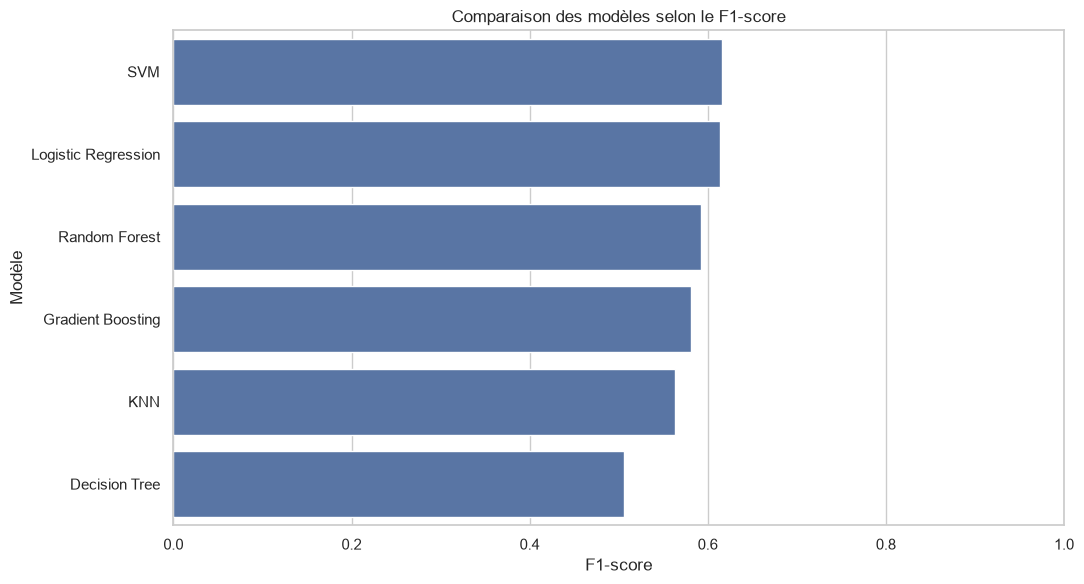

In [26]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df.sort_values("F1-score", ascending=False),
    x="F1-score",
    y="Model"
)

plt.title("Comparaison des modèles selon le F1-score")
plt.xlabel("F1-score")
plt.ylabel("Modèle")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 9. Validation croisée (Cross Validation)

La validation croisée à 5 folds divise les données d'entraînement en cinq parties. Chaque partie est utilisée une fois pour valider le modèle, tandis que les autres servent à l'entraînement.

Cela permet d'observer si les performances sont relativement stables selon les divisions des données.

In [27]:
cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean F1-score": scores.mean(),
        "Std F1-score": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        by="Mean F1-score",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Model,Mean F1-score,Std F1-score
0,Logistic Regression,0.6327,0.0253
1,SVM,0.6214,0.0195
2,Random Forest,0.6040,0.0180
3,Gradient Boosting,0.5864,0.0293
4,KNN,0.5440,0.0209
5,Decision Tree,0.4975,0.0257


## 10. Sélection automatique du meilleur modèle

Pour cette première comparaison, nous sélectionnons le modèle ayant le meilleur F1-score sur le jeu de test. Dans une version plus rigoureuse, le choix des hyperparamètres et du modèle se ferait sur validation/cross-validation, et le test serait utilisé une seule fois pour l'évaluation finale.

In [28]:
best_model_name = results_df.loc[
    results_df["F1-score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

best_f1 = results_df.loc[
    results_df["Model"] == best_model_name,
    "F1-score"
].iloc[0]

print("Meilleur modèle :", best_model_name)
print(f"F1-score : {best_f1:.4f}")

Meilleur modèle : SVM
F1-score : 0.6155


## 11. Rapport de classification

In [29]:
y_best_pred = best_model.predict(X_test)

print("Classification Report :\\n")
print(
    classification_report(
        y_test,
        y_best_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Classification Report :\n
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.77      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



## 12. Matrice de confusion

La matrice de confusion permet d'analyser les erreurs :
- **True Negative** : le client reste et le modèle prédit `No Churn`.
- **True Positive** : le client part et le modèle prédit `Churn`.
- **False Positive** : le modèle prédit un départ alors que le client reste.
- **False Negative** : le client part, mais le modèle ne détecte pas son départ.

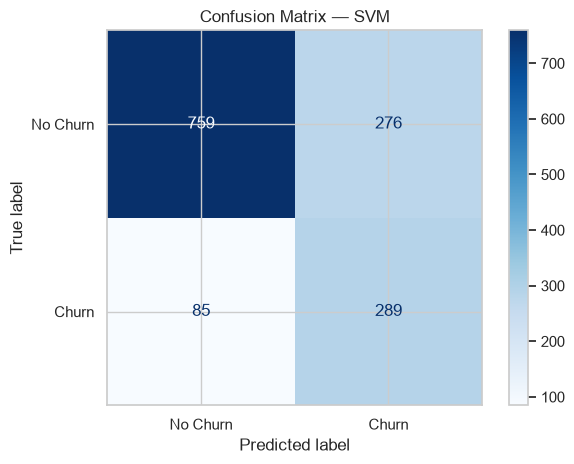

In [30]:
cm = confusion_matrix(y_test, y_best_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 13. Courbes ROC

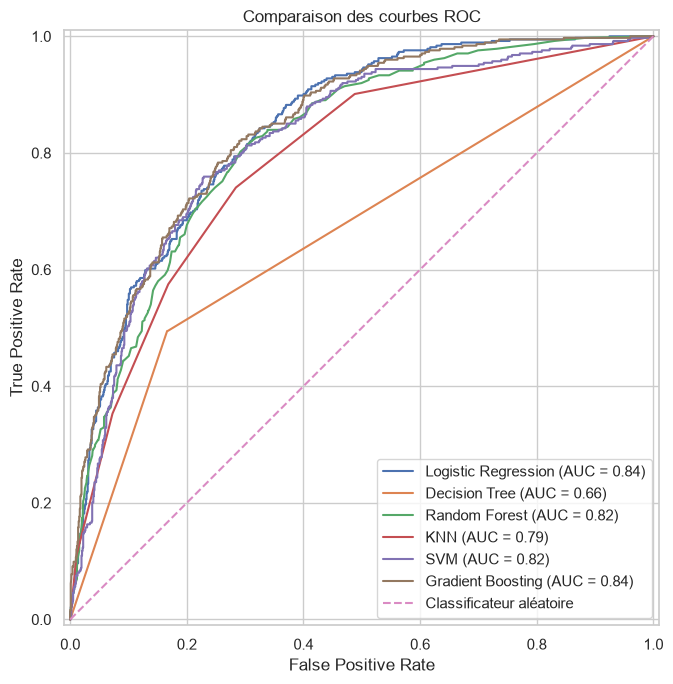

In [31]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificateur aléatoire"
)

ax.set_title("Comparaison des courbes ROC")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 14. Sauvegarde des résultats de comparaison

In [32]:
results_path = REPORTS_DIR / "model_comparison.csv"
cv_path = REPORTS_DIR / "cross_validation_results.csv"

results_df.sort_values(
    by="F1-score",
    ascending=False
).to_csv(results_path, index=False)

cv_df.sort_values(
    by="Mean F1-score",
    ascending=False
).to_csv(cv_path, index=False)

print("Résultats sauvegardés :")
print(results_path)
print(cv_path)

Résultats sauvegardés :
C:\Users\Octinz\Documents\automl-mlops-platform\reports\model_comparison.csv
C:\Users\Octinz\Documents\automl-mlops-platform\reports\cross_validation_results.csv


## 15. Sauvegarde du meilleur modèle

In [33]:
best_model_path = MODELS_DIR / "best_model.joblib"

joblib.dump(best_model, best_model_path)

print("Meilleur modèle sauvegardé !")
print("Nom :", best_model_name)
print("Chemin :", best_model_path)

Meilleur modèle sauvegardé !
Nom : SVM
Chemin : C:\Users\Octinz\Documents\automl-mlops-platform\models\best_model.joblib


## 16. Vérification des fichiers générés

In [34]:
generated_files = [
    REPORTS_DIR / "model_comparison.csv",
    REPORTS_DIR / "cross_validation_results.csv",
    MODELS_DIR / "best_model.joblib"
]

for file in generated_files:
    print(file.relative_to(PROJECT_ROOT), "->", file.exists())

reports\model_comparison.csv -> True
reports\cross_validation_results.csv -> True
models\best_model.joblib -> True


# Conclusion

Dans ce notebook, nous avons réalisé la phase de **Model Training & AutoML**.

Les principales étapes réalisées :
- Chargement des données prétraitées.
- Initialisation de plusieurs algorithmes de Machine Learning.
- Entraînement des modèles.
- Évaluation avec Accuracy, Precision, Recall, F1-score et ROC-AUC.
- Comparaison des performances.
- Validation croisée avec 5 folds.
- Sélection du meilleur modèle selon le F1-score.
- Sauvegarde des résultats et du meilleur modèle.

Le meilleur modèle est sauvegardé dans le dossier `models` sous le nom `best_model.joblib`.

Il sera utilisé dans les prochaines étapes du projet : **Model Evaluation, MLOps et Deployment**.